In [6]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import AxesGrid
from salvaged import *
run = 'earth2/'
datadir = '../data/'+run
prefix=''

In [69]:
ptimes=[9.9]
tim=[2250.0]
t_eps=0.001
ThisPatch = RamsesMHDPatch
verbose=False
skipped=[]
orbit_radius_au = 1.0
omega = [0.0,0.0,1.0]
pl_pos= [0.0,1.0,0.0]
v_headwind = 0.0   # the headwind the planet feels
v_accretion = 0.0  # accretion rate
density_cgs=3e-12  # external density
pl_rad=27
pl_mass=1.0
bond_rad = pl_mass*sc.scaling().g*0.2
hill_rad = 235
times=np.linspace(1,99,99)/10.
    
pat = get_data(time=tim[0],t_eps=t_eps,datadir=datadir)
patches=velocities(pat)


159 patches collected for time 2250.0


yt : [INFO     ] 2017-03-08 22:05:23,131 Parameters: current_time              = 0.0
yt : [INFO     ] 2017-03-08 22:05:23,132 Parameters: domain_dimensions         = [24 24 24]
yt : [INFO     ] 2017-03-08 22:05:23,133 Parameters: domain_left_edge          = [-2700. -2700. -2700.]
yt : [INFO     ] 2017-03-08 22:05:23,134 Parameters: domain_right_edge         = [ 2700.  2700.  2700.]
yt : [INFO     ] 2017-03-08 22:05:23,136 Parameters: cosmological_simulation   = 0.0
yt : [INFO     ] 2017-03-08 22:05:23,598 xlim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-08 22:05:23,599 ylim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-08 22:05:23,600 xlim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-08 22:05:23,602 ylim = -2700.000000 2700.000000
yt : [INFO     ] 2017-03-08 22:05:23,604 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



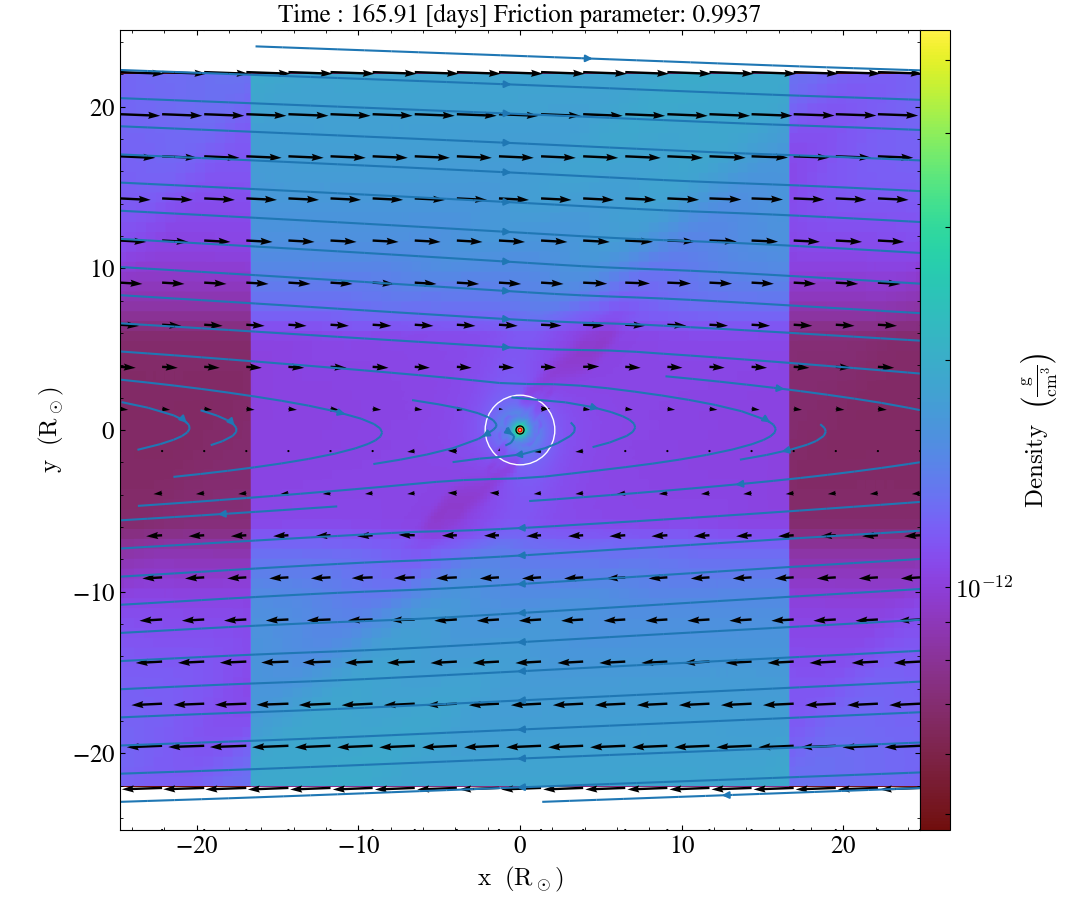

In [70]:
dic=make_yt_dict(patches)
n=patches[0].n
sz=2700
ds = load_yt(dic,n,sz)
frc_time = 1000.
f_sc = 1-np.exp(-(tim[0]/frc_time)**2)
fig = plt.figure()
#carg=dict

#plt.savefig('multiplot_2x2_coordaxes_slice.png')
#ds.current_time=patches[0].time*sc.scaling().t/3600.
slc=yt.SlicePlot(ds=ds,normal="z",fields=["density"],center=[0,0,40])
slc.annotate_velocity(factor=40, normalize=False)
slc.annotate_streamlines('velocity_x', 'velocity_y')
slc.time_unit=sc.scaling().t
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=1, circle_args={'color':'magenta'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=pl_rad, circle_args={'color':'black'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=bond_rad, circle_args={'color':'red'})
slc.annotate_sphere(center=[0.0, 0.0, 0.0], radius=hill_rad, circle_args={'color':'white'})
slc.current_time=patches[0].time*sc.scaling().t/3600./24.
slc.annotate_title("Time : %.2f [days]" % (patches[0].time*sc.scaling().t/3600./24.)+" Friction parameter: %.4f" %f_sc)
#slc.annotate_timestamp()
#slc.zoom(10)
slc.show()

yt : [INFO     ] 2017-03-08 22:09:43,342 Making a fixed resolution buffer of (('gas', 'density')) 800 by 800



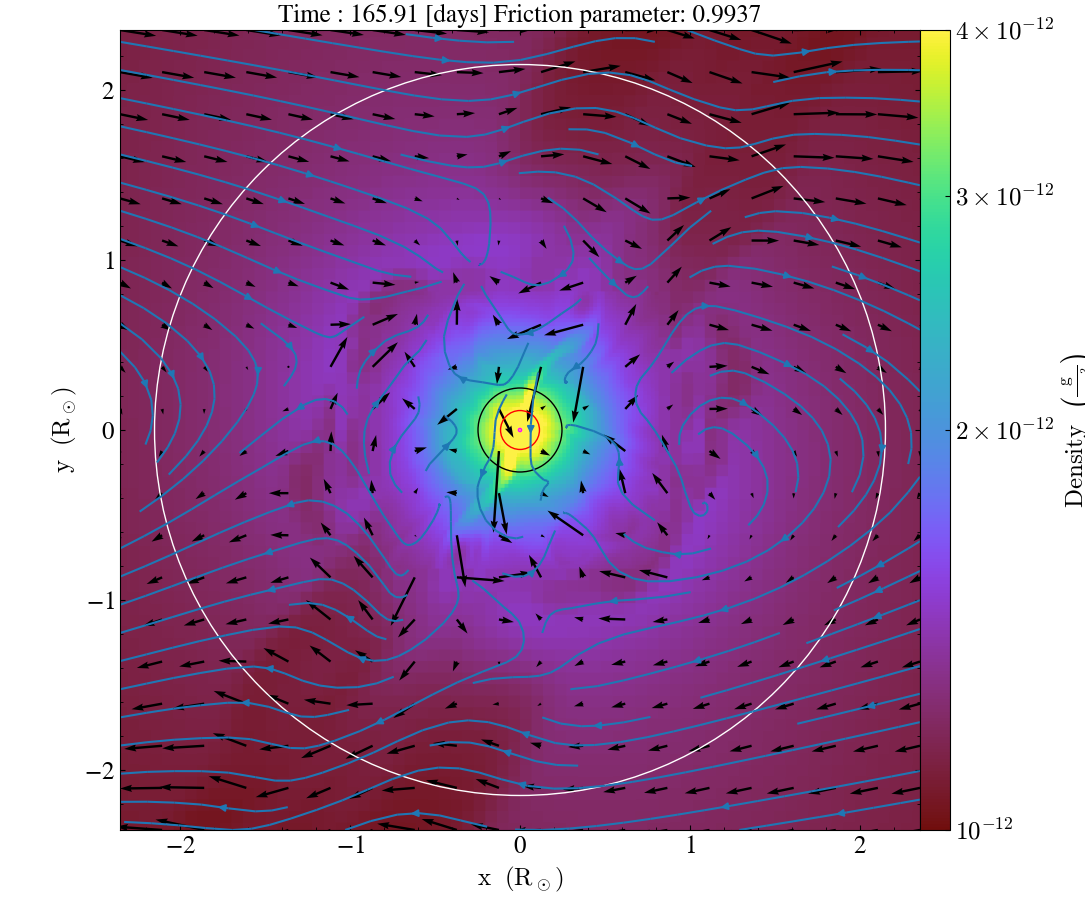

In [87]:
slc.zoom(5)
slc.set_zlim('density',1e-12,4e-12)
slc.show()

In [67]:
hill_rad

235

In [10]:
slc.save('earth_damped_0.png')

yt : [INFO     ] 2017-03-03 15:47:17,555 Saving plot earth_damped_0.png


['earth_damped_0.png']

In [201]:
f_sc = np.exp(-(2000./1000.)**2)

In [202]:
f_sc, frc_time

(0.018315638888734179, 2000.0)

In [203]:
np.exp(-1.)

0.36787944117144233

In [59]:
sc.scaling().g*0.2

12.510172971276095